# Telco Customer Churn Analysis

**Goal:** find out who churns, how much revenue it costs, and which customer segments to target for retention.

**Dataset:** IBM Telco Customer Churn (7,043 customers, 21 columns).
The SQL version of this analysis (`02_churn_analysis.sql`) uses the same definitions, so the numbers should match.

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, accuracy_score, classification_report

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

# Path to the CSV (same folder as this notebook by default)
CSV_PATH = "../data/WA_Fn-UseC_-Telco-Customer-Churn.csv"

BAR_COLOR = "#2E6F9E"
ACCENT = "#C8553D"

## 1. Load and inspect

In [4]:
df = pd.read_csv(CSV_PATH)
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


## 2. Clean the data

`TotalCharges` is read as text because 11 rows contain a blank space. These are all brand-new customers with `tenure = 0`
(they haven't been billed yet), so a missing value is the right representation. In SQL these rows are `NULL` too.

In [6]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

blank = df[df["TotalCharges"].isna()]
print("Rows with missing TotalCharges:", len(blank))
print("Their tenure values:", blank["tenure"].unique())

df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)

print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

Rows with missing TotalCharges: 11
Their tenure values: [0]
Duplicate customer IDs: 0


## 3. Overall churn

In [7]:
total = len(df)
churned = df["ChurnFlag"].sum()
overall_rate = churned / total * 100
print(f"Customers: {total:,}")
print(f"Churned:   {churned:,}")
print(f"Churn rate: {overall_rate:.2f}%")

Customers: 7,043
Churned:   1,869
Churn rate: 26.54%


## 4. Churn rate by segment

In [8]:
def churn_by(col, data=None, order=None):
    d = df if data is None else data
    out = (d.groupby(col)["ChurnFlag"]
             .agg(customers="count", churned="sum")
             .assign(churn_rate_pct=lambda t: (100 * t["churned"] / t["customers"]).round(2)))
    if order is not None:
        out = out.loc[order]
    else:
        out = out.sort_values("churn_rate_pct", ascending=False)
    return out

df["tenure_band"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, np.inf],
    labels=["0-12 months", "13-24 months", "25-48 months", "49+ months"],
)

contract_tbl = churn_by("Contract")
internet_tbl = churn_by("InternetService")
payment_tbl  = churn_by("PaymentMethod")
tenure_tbl   = churn_by("tenure_band", order=["0-12 months", "13-24 months", "25-48 months", "49+ months"])

print("By contract");          print(contract_tbl)
print("\nBy internet service"); print(internet_tbl)
print("\nBy payment method");   print(payment_tbl)
print("\nBy tenure band");      print(tenure_tbl)

By contract
                customers  churned  churn_rate_pct
Contract                                          
Month-to-month       3875     1655           42.71
One year             1473      166           11.27
Two year             1695       48            2.83

By internet service
                 customers  churned  churn_rate_pct
InternetService                                    
Fiber optic           3096     1297           41.89
DSL                   2421      459           18.96
No                    1526      113            7.40

By payment method
                           customers  churned  churn_rate_pct
PaymentMethod                                                
Electronic check                2365     1071           45.29
Mailed check                    1612      308           19.11
Bank transfer (automatic)       1544      258           16.71
Credit card (automatic)         1522      232           15.24

By tenure band
              customers  churned  churn_rate_

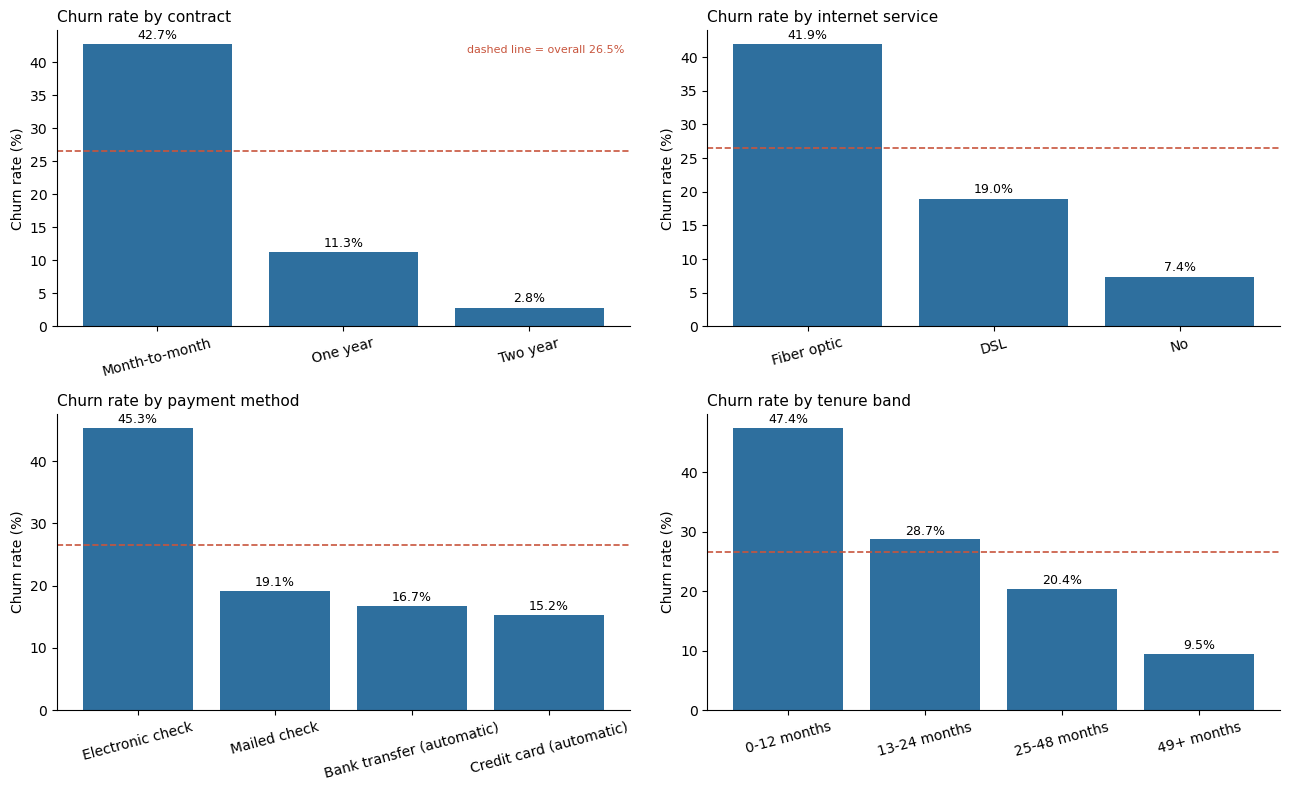

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
tables = [("Contract", contract_tbl), ("Internet service", internet_tbl),
          ("Payment method", payment_tbl), ("Tenure band", tenure_tbl)]

for ax, (title, t) in zip(axes.ravel(), tables):
    bars = ax.bar(t.index.astype(str), t["churn_rate_pct"], color=BAR_COLOR)
    ax.axhline(overall_rate, color=ACCENT, linestyle="--", linewidth=1.2)
    ax.set_title(f"Churn rate by {title.lower()}", fontsize=11, loc="left")
    ax.set_ylabel("Churn rate (%)")
    ax.tick_params(axis="x", labelrotation=15)
    for b, v in zip(bars, t["churn_rate_pct"]):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.8, f"{v:.1f}%", ha="center", fontsize=9)
    ax.spines[["top", "right"]].set_visible(False)

axes[0, 0].text(0.99, 0.95, f"dashed line = overall {overall_rate:.1f}%", transform=axes[0, 0].transAxes,
                ha="right", va="top", fontsize=8, color=ACCENT)
plt.tight_layout()
plt.show()

## 5. Do add-on services protect against churn?

Only customers who have internet service are compared (customers with no internet can't buy these add-ons).

In [10]:
internet_users = df[df["InternetService"] != "No"]
addons = ["OnlineSecurity", "TechSupport", "OnlineBackup", "DeviceProtection"]

rows = []
for a in addons:
    t = churn_by(a, data=internet_users, order=["No", "Yes"])
    for val in ["No", "Yes"]:
        rows.append({"service": a, "has_service": val,
                     "customers": t.loc[val, "customers"],
                     "churned": t.loc[val, "churned"],
                     "churn_rate_pct": t.loc[val, "churn_rate_pct"]})
addon_tbl = pd.DataFrame(rows)
print(addon_tbl.to_string(index=False))

         service has_service  customers  churned  churn_rate_pct
  OnlineSecurity          No       3498     1461           41.77
  OnlineSecurity         Yes       2019      295           14.61
     TechSupport          No       3473     1446           41.64
     TechSupport         Yes       2044      310           15.17
    OnlineBackup          No       3088     1233           39.93
    OnlineBackup         Yes       2429      523           21.53
DeviceProtection          No       3095     1211           39.13
DeviceProtection         Yes       2422      545           22.50


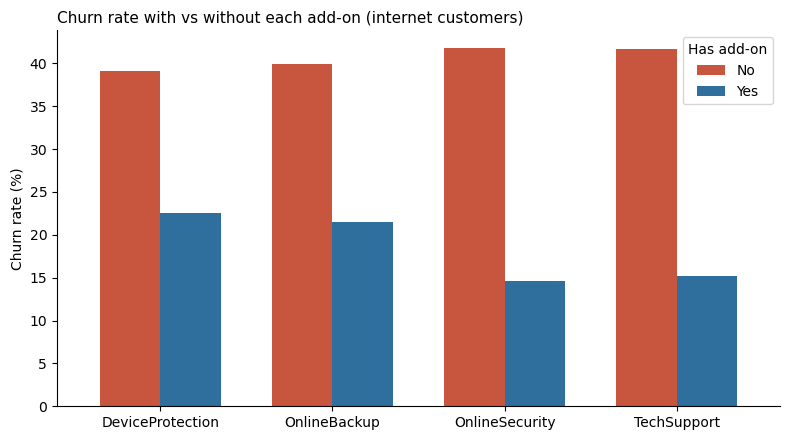

In [11]:
pivot = addon_tbl.pivot(index="service", columns="has_service", values="churn_rate_pct")[["No", "Yes"]]
ax = pivot.plot(kind="bar", figsize=(8, 4.5), color=[ACCENT, BAR_COLOR], width=0.7)
ax.set_title("Churn rate with vs without each add-on (internet customers)", loc="left", fontsize=11)
ax.set_ylabel("Churn rate (%)")
ax.set_xlabel("")
ax.legend(title="Has add-on")
ax.tick_params(axis="x", labelrotation=0)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 6. Revenue impact

In [12]:
rev = (df.groupby("Churn")["MonthlyCharges"]
         .agg(customers="count", avg_monthly_charge="mean", total_monthly_revenue="sum")
         .round(2))
print(rev)

churned_mrr = df.loc[df["Churn"] == "Yes", "MonthlyCharges"].sum()
total_mrr = df["MonthlyCharges"].sum()
print(f"\nChurned monthly revenue: {churned_mrr:,.2f}")
print(f"Total monthly revenue:   {total_mrr:,.2f}")
print(f"Share of monthly revenue lost: {100 * churned_mrr / total_mrr:.2f}%")

       customers  avg_monthly_charge  total_monthly_revenue
Churn                                                      
No          5174               61.27              316985.75
Yes         1869               74.44              139130.85

Churned monthly revenue: 139,130.85
Total monthly revenue:   456,116.60
Share of monthly revenue lost: 30.50%


## 7. Demographics

In [13]:
df["SeniorLabel"] = np.where(df["SeniorCitizen"] == 1, "Yes", "No")
for col in ["SeniorLabel", "Partner", "Dependents"]:
    print(col)
    print(churn_by(col, order=["No", "Yes"]), "\n")

SeniorLabel
             customers  churned  churn_rate_pct
SeniorLabel                                    
No                5901     1393           23.61
Yes               1142      476           41.68 

Partner
         customers  churned  churn_rate_pct
Partner                                    
No            3641     1200           32.96
Yes           3402      669           19.66 

Dependents
            customers  churned  churn_rate_pct
Dependents                                    
No               4933     1543           31.28
Yes              2110      326           15.45 



## 8. Highest-risk segments

In [14]:
seg = (df.groupby(["Contract", "InternetService"])["ChurnFlag"]
         .agg(customers="count", churned="sum")
         .assign(churn_rate_pct=lambda t: (100 * t["churned"] / t["customers"]).round(2))
         .sort_values("churn_rate_pct", ascending=False)
         .reset_index())
seg.insert(0, "risk_rank", seg["churn_rate_pct"].rank(method="min", ascending=False).astype(int))
print(seg.to_string(index=False))

 risk_rank       Contract InternetService  customers  churned  churn_rate_pct
         1 Month-to-month     Fiber optic       2128     1162           54.61
         2 Month-to-month             DSL       1223      394           32.22
         3       One year     Fiber optic        539      104           19.29
         4 Month-to-month              No        524       99           18.89
         5       One year             DSL        570       53            9.30
         6       Two year     Fiber optic        429       31            7.23
         7       One year              No        364        9            2.47
         8       Two year             DSL        628       12            1.91
         9       Two year              No        638        5            0.78


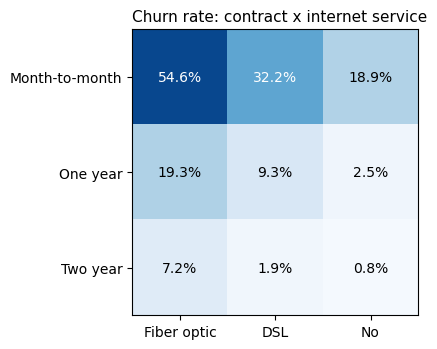

In [15]:
heat = (df.pivot_table(index="Contract", columns="InternetService", values="ChurnFlag", aggfunc="mean") * 100).round(1)
heat = heat.loc[["Month-to-month", "One year", "Two year"], ["Fiber optic", "DSL", "No"]]

fig, ax = plt.subplots(figsize=(6.5, 3.6))
im = ax.imshow(heat.values, cmap="Blues", vmin=0, vmax=60)
ax.set_xticks(range(heat.shape[1])); ax.set_xticklabels(heat.columns)
ax.set_yticks(range(heat.shape[0])); ax.set_yticklabels(heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        ax.text(j, i, f"{v:.1f}%", ha="center", va="center", color="white" if v > 30 else "black")
ax.set_title("Churn rate: contract x internet service", loc="left", fontsize=11)
plt.tight_layout()
plt.show()

In [16]:
storm = df[(df["Contract"] == "Month-to-month")
           & (df["InternetService"] == "Fiber optic")
           & (df["PaymentMethod"] == "Electronic check")]
print(f"Month-to-month + Fiber optic + Electronic check")
print(f"Customers: {len(storm):,} | Churned: {storm['ChurnFlag'].sum():,} | "
      f"Churn rate: {100 * storm['ChurnFlag'].mean():.2f}%")

early = df[(df["Churn"] == "Yes") & (df["tenure"] <= 12)]
print(f"\nShare of all churners who left within their first 12 months: "
      f"{100 * len(early) / churned:.2f}%")

Month-to-month + Fiber optic + Electronic check
Customers: 1,307 | Churned: 789 | Churn rate: 60.37%

Share of all churners who left within their first 12 months: 55.48%


## 9. Distributions: tenure and monthly charges

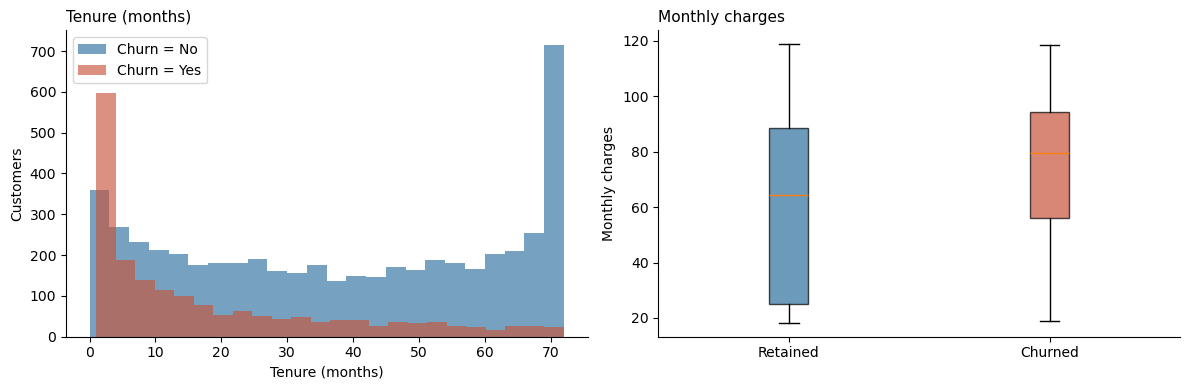

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for label, color in [("No", BAR_COLOR), ("Yes", ACCENT)]:
    axes[0].hist(df.loc[df["Churn"] == label, "tenure"], bins=24, alpha=0.65, color=color,
                 label=f"Churn = {label}")
axes[0].set_title("Tenure (months)", loc="left", fontsize=11)
axes[0].set_xlabel("Tenure (months)"); axes[0].set_ylabel("Customers"); axes[0].legend()

data = [df.loc[df["Churn"] == "No", "MonthlyCharges"], df.loc[df["Churn"] == "Yes", "MonthlyCharges"]]
bp = axes[1].boxplot(data, patch_artist=True)
axes[1].set_xticks([1, 2])
axes[1].set_xticklabels(["Retained", "Churned"])
for patch, c in zip(bp["boxes"], [BAR_COLOR, ACCENT]):
    patch.set_facecolor(c); patch.set_alpha(0.7)
axes[1].set_title("Monthly charges", loc="left", fontsize=11)
axes[1].set_ylabel("Monthly charges")

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 10. Are the differences statistically real?

In [18]:
# Contract vs churn: chi-square test of independence
ct = pd.crosstab(df["Contract"], df["Churn"])
chi2, p, dof, _ = stats.chi2_contingency(ct)
print(f"Contract vs Churn: chi2 = {chi2:.1f}, dof = {dof}, p = {p:.2e}")

# Monthly charges: churned vs retained (non-parametric)
u, p2 = stats.mannwhitneyu(data[1], data[0], alternative="two-sided")
print(f"Monthly charges, churned vs retained: Mann-Whitney U p = {p2:.2e}")

# Tenure: churned vs retained
u3, p3 = stats.mannwhitneyu(df.loc[df["Churn"] == "Yes", "tenure"],
                            df.loc[df["Churn"] == "No", "tenure"], alternative="two-sided")
print(f"Tenure, churned vs retained: Mann-Whitney U p = {p3:.2e}")

Contract vs Churn: chi2 = 1184.6, dof = 2, p = 5.86e-258
Monthly charges, churned vs retained: Mann-Whitney U p = 3.31e-54
Tenure, churned vs retained: Mann-Whitney U p = 2.42e-208


## 11. Predicting churn (baseline model)

A simple logistic regression, to see which features matter most. It is a baseline for understanding drivers, not a production model.
`TotalCharges` is dropped because it is mostly `tenure x MonthlyCharges` and has the 11 missing values.

In [19]:
features = df.drop(columns=["customerID", "Churn", "ChurnFlag", "TotalCharges", "tenure_band", "SeniorLabel"])
X = pd.get_dummies(features, drop_first=True)
y = df["ChurnFlag"]

# Scale the numeric columns so coefficients are comparable
num_cols = ["tenure", "MonthlyCharges"]
X[num_cols] = (X[num_cols] - X[num_cols].mean()) / X[num_cols].std()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)

model = LogisticRegression(max_iter=2000)
model.fit(X_train.astype(float), y_train)

proba = model.predict_proba(X_test.astype(float))[:, 1]
pred = (proba >= 0.5).astype(int)

print(f"ROC AUC:  {roc_auc_score(y_test, proba):.3f}")
print(f"Accuracy: {accuracy_score(y_test, pred):.3f}")
print()
print(classification_report(y_test, pred, target_names=["Retained", "Churned"]))

ROC AUC:  0.845
Accuracy: 0.801

              precision    recall  f1-score   support

    Retained       0.85      0.89      0.87      1294
     Churned       0.65      0.55      0.59       467

    accuracy                           0.80      1761
   macro avg       0.75      0.72      0.73      1761
weighted avg       0.79      0.80      0.80      1761



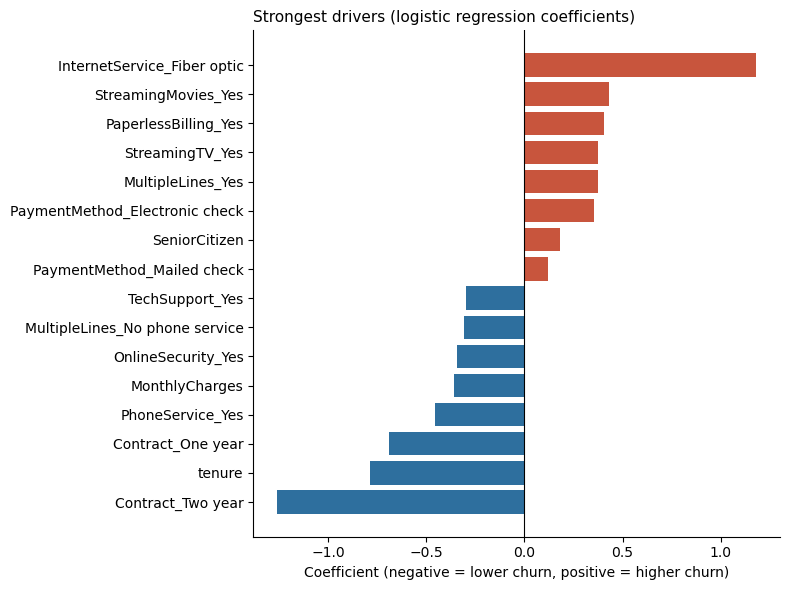

In [20]:
coefs = pd.Series(model.coef_[0], index=X.columns).sort_values()
top = pd.concat([coefs.head(8), coefs.tail(8)])

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top.values, color=[BAR_COLOR if v < 0 else ACCENT for v in top.values])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Strongest drivers (logistic regression coefficients)", loc="left", fontsize=11)
ax.set_xlabel("Coefficient (negative = lower churn, positive = higher churn)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 12. Key findings

1. **Overall churn** is 26.54% (1,869 of 7,043 customers).
2. **Contract type is the biggest lever.** Month-to-month customers churn at 42.71%, compared with 11.27% for one-year and 2.83% for two-year contracts.
3. **New customers are the most at risk.** 47.44% of customers in their first 12 months churn, and 55.48% of all churners left within their first year.
4. **Fiber optic and electronic-check customers churn the most.** Fiber optic churns at 41.89% (DSL 18.96%). Electronic check churns at 45.29% (credit card automatic 15.24%).
5. **Add-ons go with lower churn.** Customers with Online Security churn at 14.61% vs 41.77% without. Tech Support: 15.17% vs 41.64%.
6. **Revenue impact.** Churned customers pay more per month (74.44 vs 61.27 on average), so churn removes 30.50% of monthly revenue while losing only 26.54% of customers.
7. **Highest-risk profile.** Month-to-month + fiber optic + electronic check: 1,307 customers with a 60.37% churn rate.

**Recommendations**
- Offer incentives to move month-to-month customers onto one-year contracts.
- Build a first-year onboarding and check-in programme.
- Bundle Online Security and Tech Support into fiber plans.
- Encourage electronic-check customers to switch to automatic payment.

*Note: add-on services and churn are associated, not proven causes. Customers who buy add-ons may also be more engaged to begin with.*